# Project 3, Read it for me

**AI Fundamentals, Session 3**

Hold a document up to your webcam and get data back: a receipt becomes a row in your
expenses, a business card becomes a contact, a scene becomes a description for someone who
cannot see it. One model does all of it, a **vision language model**: a language model
that also reads images.

It runs on your laptop through Ollama. That matters here: receipts, contracts and student
cards are exactly the documents you should not upload to somebody else's server.

You will:

- **A** Ask a local model questions about a photo, and check its answers
- **B** Turn a receipt into a table, and let code check the arithmetic
- **C** Show it a photo that is not a receipt, and see what it invents
- **D** Build a webcam app: hold something up, get data back

The point: a general model reads anything, slowly, and sometimes makes things up. The fix
is not trusting it more. It is giving it a way to say no, and checking with code whatever
code can check.

In [2]:
import io  # turns an image into bytes in memory, without saving a file
import time  # to measure how long each answer takes

import ollama  # talks to the models Ollama runs on your laptop
import pandas as pd  # tables
from IPython.display import Image as Picture  # shows a picture in the notebook
from PIL import Image  # opening and converting images
from pydantic import BaseModel, Field  # describes the shape of the answer we want back

from settings import CHAT_MODEL, OLLAMA_OPTIONS, check_ollama  # settings.py, next to this notebook

check_ollama(CHAT_MODEL)
print("model:", CHAT_MODEL)

Ollama is running, models ready: qwen3.5:4b
model: qwen3.5:4b


---
## Part A, ask about a photo

One function does all the talking. It sends a question and an image, and returns the
answer. Two settings in it deserve a word:

- **temperature 0** makes the model pick the most likely next word every time. For reading
  a document you want no creativity, and you want the same answer when you ask twice
- **think=False** asks for the answer directly. Some models can reason step by step first,
  which helps with puzzles but triples the waiting time here

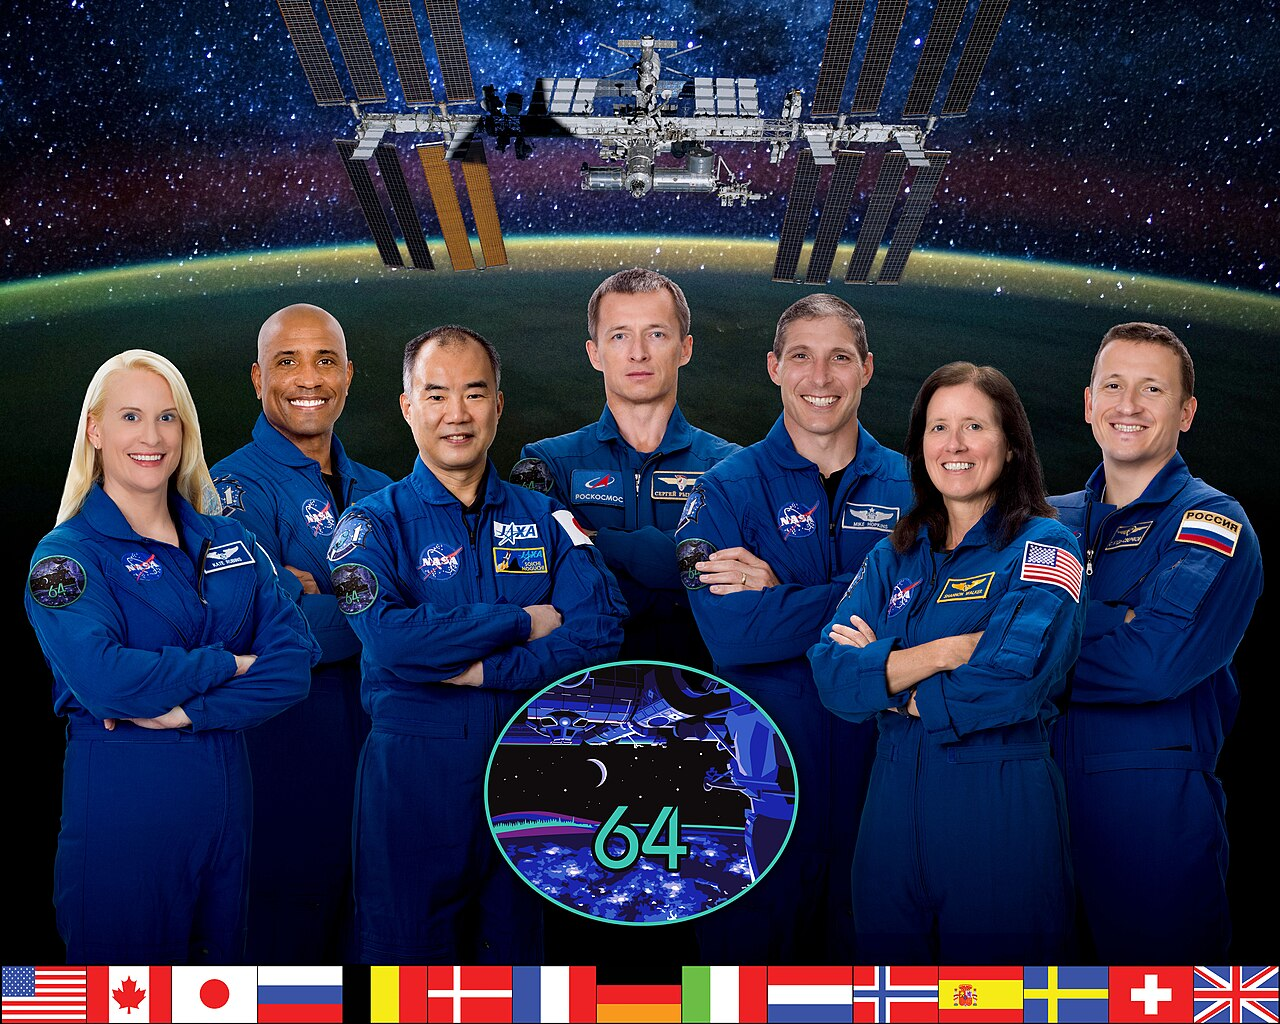

In [3]:
def to_image(picture):
    """Ollama accepts a file path, or the bytes of a JPEG. Convert a webcam frame to bytes."""
    if isinstance(picture, str):          # already a file path: Ollama reads the file itself
        return picture
    buffer = io.BytesIO()                 # a file that lives in memory
    Image.fromarray(picture).save(buffer, format="JPEG")
    return buffer.getvalue()


def ask(question, picture, schema=None):
    """Send one question and one picture to the local model, and return its answer."""
    response = ollama.chat(
        model=CHAT_MODEL,
        messages=[{"role": "user", "content": question, "images": [to_image(picture)]}],
        format=schema.model_json_schema() if schema else None,   # used from Part B on
        options={**OLLAMA_OPTIONS, "temperature": 0},             # ** merges two dictionaries
        think=False,
    )
    return response.message.content


def show(path, width=600):
    """Display an image file in the notebook, 600 pixels wide."""
    return Picture(filename=path, width=width)


show("data/images/crew.jpg")

In [4]:
start = time.time()
print(ask("Describe this photo in two sentences for someone who cannot see it.", "data/images/crew.jpg"))
print(f"\n{time.time() - start:.1f} seconds")

This image features a group of seven astronauts from various countries, including the United States, Russia, Japan, and Canada, standing together in blue flight suits against a backdrop of Earth and the International Space Station. At the bottom, flags representing their respective nations are displayed, while a circular emblem with the number "64" highlights this as part of a series commemorating space exploration milestones.

5.8 seconds


It reads well. Now check it the way you would check a colleague: claim by claim, against
the photo. How many people, which countries, how many flags? Small models describe the
gist convincingly and get details, especially counts, wrong.

In [5]:
start = time.time()
print(ask("In two short sentences: how many people are in this photo, and how many flags are at the bottom?",
          "data/images/crew.jpg"))
print(f"\n{time.time() - start:.1f} seconds")

 There are seven astronauts in the photo. At the bottom, there are twelve flags representing different countries.

4.3 seconds


The right answers are 7 people and 15 flags. Whatever it said, notice how sure it sounded.
A model gives a wrong count in the same confident tone as a right one, so its tone tells
you nothing.

Compare that with Project 1. RT-DETR counted the people in about 40 milliseconds and knows
80 words. This model takes seconds, and will answer any question you can type. That is
the trade-off between a **specialist** model and a **generalist** one, and real systems
often use both: the fast one for the routine, the slow one for everything else.

**Exercise A1.** Ask about the coffee photo, `data/images/coffee.jpg`: what is on the
saucer, and what is the table made of? Then ask something the photo cannot answer, such as
the price of the coffee. Does it admit that it cannot know?

---
## Part B, from a receipt to a table

A description is text for people. Your expenses spreadsheet wants data: the shop, the
date, every line and the total, always under the same names. So we hand the model a form
to fill in.

The form is a **pydantic** class. Each line is a field with a name and a type, and
`Field(description=...)` adds a hint for the model. Ollama turns the class into a schema
and forces the answer into exactly that shape, so it always parses.

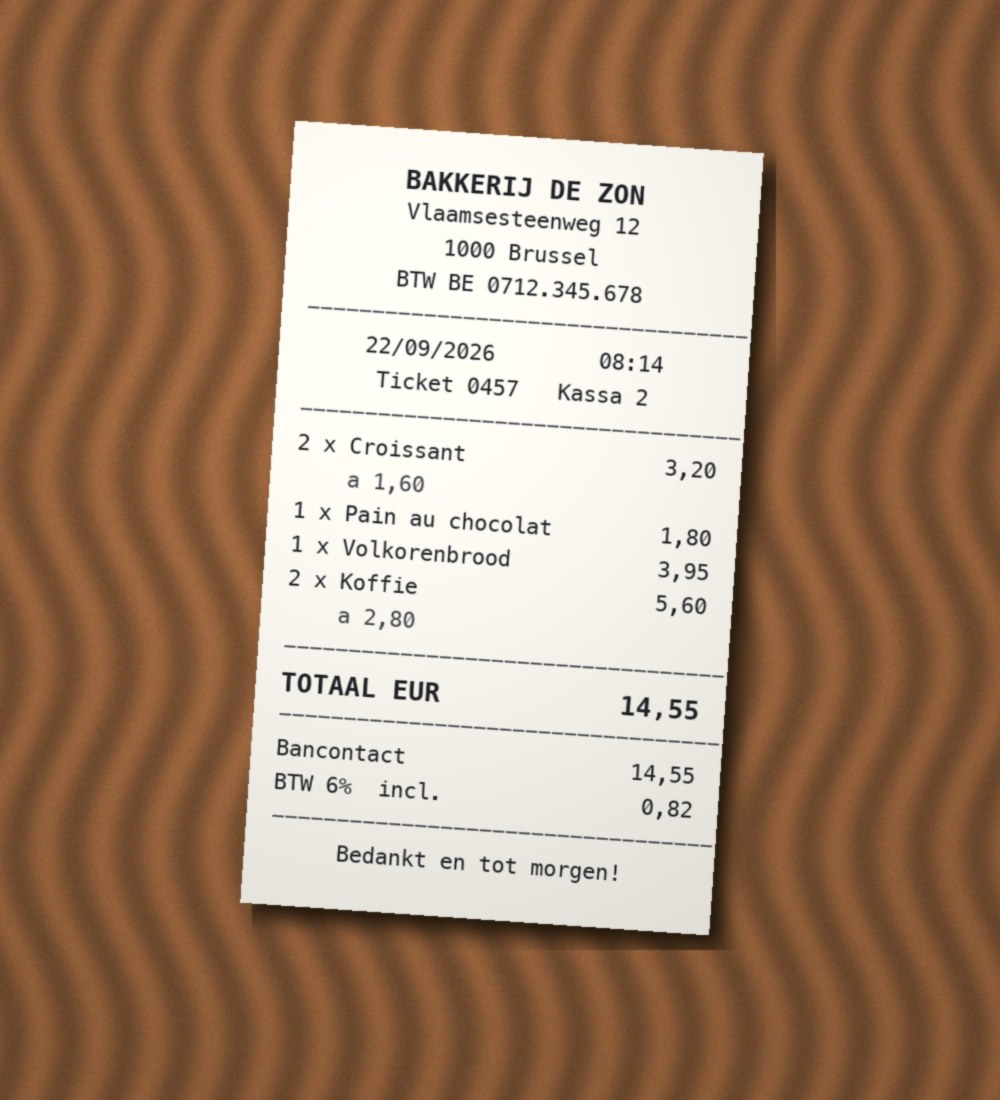

In [6]:
class Line(BaseModel):
    """One line of a receipt."""
    name: str
    quantity: int
    line_total: float = Field(description="the price of this line in euro")


class Receipt(BaseModel):
    """The whole receipt."""
    shop: str
    date: str = Field(description="the date, written as YYYY-MM-DD")
    lines: list[Line]                     # a list of Line objects, as many as there are
    total: float
    payment_method: str


show("data/images/receipt.jpg")

In [7]:
start = time.time()
answer = ask("Extract this receipt.", "data/images/receipt.jpg", schema=Receipt)
print(f"{time.time() - start:.1f} seconds\n")
print(answer)

8.5 seconds

{
  "shop": "BAKKERIJ DE ZON",
  "date": "22/09/2026",
  "lines": [
    {
      "name": "Croissant",
      "quantity": 2,
      "line_total": 3.2
    },
    {
      "name": "Pain au chocolat",
      "quantity": 1,
      "line_total": 1.8
    },
    {
      "name": "Volkorenbrood",
      "quantity": 1,
      "line_total": 3.95
    },
    {
      "name": "Koffie",
      "quantity": 2,
      "line_total": 5.6
    }
  ],
  "total": 14.55,
  "payment_method": "Bancontact"
}


In [8]:
# The answer is JSON text in the shape of Receipt, so pydantic turns it into an object.
receipt = Receipt.model_validate_json(answer)

# A table of the lines. model_dump() turns each Line into a dictionary pandas understands.
table = pd.DataFrame([line.model_dump() for line in receipt.lines])
table

,name,quantity,line_total
0,Croissant,2,3.20
1,Pain au chocolat,1,1.80
2,Volkorenbrood,1,3.95
3,Koffie,2,5.60


The receipt is fictional, the photo was made for this course, and the model has never
seen it. The amounts are Belgian, with a decimal comma (`3,20`), and the JSON has turned
them into numbers (`3.2`). Now the part that makes this usable: **check it**.

In [9]:
lines_sum = round(table["line_total"].sum(), 2)
print("sum of the lines:", lines_sum)
print("total on receipt:", receipt.total)
print("adds up" if abs(lines_sum - receipt.total) < 0.01 else "DOES NOT ADD UP: send to a person")
print()

# We asked for YYYY-MM-DD. Did we get it? Never assume a format, test it.
try:
    print("date:", pd.to_datetime(receipt.date, format="%Y-%m-%d").date())
except ValueError:
    print(f"date {receipt.date!r} is not in the format we asked for: fix it in code, or reject it")

sum of the lines: 14.55
total on receipt: 14.55
adds up

date '22/09/2026' is not in the format we asked for: fix it in code, or reject it


A model that reads receipts will one day misread a 3 as an 8. The arithmetic check costs
nothing and catches exactly that. Whenever part of the answer can be verified by code,
verify it, and send only the failures to a person.

**Exercise B1.** If the date came back in the wrong format, convert it in code instead:
`pd.to_datetime(receipt.date, dayfirst=True)` reads Belgian dates.

---
## Part C, a photo that is not a receipt

The form says every receipt has a shop, a date and a total. So what happens when there is
no receipt?

In [10]:
print(ask("Extract this receipt.", "data/images/coffee.jpg", schema=Receipt))

{
  "shop": "Cafe",
  "date": "2023-10-05",
  "lines": [
    {"name": "Espresso", "quantity": 1, "line_total": 4.5},
    {"name": "Spoon", "quantity": 1, "line_total": 0.5}
  ],
  "total": 5.0,
  "payment_method": "Cash"
}


Read what came back. If it named a shop and a price, it invented them: the photo shows a
cup of coffee and nothing else. That is not a bug in the model. **We demanded a shop and a
total, so we got a shop and a total.** The form left it no way to say *this is not a
receipt*.

So give it one. The new first field asks the question before anything else, and the other
fields may now be empty (`None`).

In [11]:
class MaybeReceipt(BaseModel):
    is_receipt: bool = Field(description="false if the photo does not show a receipt")
    shop: str | None                      # "str | None" means: a text, or nothing
    total: float | None
    lines: list[Line]


for photo in ["data/images/coffee.jpg", "data/images/receipt.jpg"]:
    result = MaybeReceipt.model_validate_json(ask("Extract this receipt, if there is one.", photo, MaybeReceipt))
    print(f"{photo:<28} is a receipt: {result.is_receipt!s:<6} shop: {result.shop}   total: {result.total}")

data/images/coffee.jpg       is a receipt: False  shop: None   total: None


data/images/receipt.jpg      is a receipt: True   shop: BAKKERIJ DE ZON   total: 14.55


The same model, the same photo, a different form, and the invention is gone. Designing the
form is designing the system: what may the model answer, and what may it say when the
answer does not exist?

---
## Part D, the webcam app

Hold something up to the camera, take a picture, pick what you want, and press **Read it**.
The webcam here takes single pictures instead of a stream, because every answer takes a
few seconds anyway.

In [12]:
import gradio as gr


class Contact(BaseModel):
    is_business_card: bool = Field(description="false if the photo does not show a business card")
    name: str | None
    job_title: str | None
    company: str | None
    email: str | None
    phone: str | None


# Each task is a question, plus a form when we want data back instead of text.
TASKS = {
    "Describe it for someone who cannot see it": ("Describe this photo in three sentences for someone who cannot see it.", None),
    "Read all the text": ("Write out all the text you can read in this photo, line by line. Write nothing else.", None),
    "Receipt to data": ("Extract this receipt, if there is one.", MaybeReceipt),
    "Business card to contact": ("Extract the contact details, if this is a business card.", Contact),
    "My own question": (None, None),
}


def read_it(picture, task, own_question):
    if picture is None:
        return "Take a picture first: click the camera icon under the webcam."
    question, schema = TASKS[task]
    question = question or own_question
    start = time.time()
    answer = ask(question, picture, schema)
    seconds = f"\n\n*{time.time() - start:.1f} seconds, {CHAT_MODEL}, on this laptop*"
    if schema is None:                    # plain text: show it as it is
        return answer + seconds
    shown = f"```json\n{answer}\n```"     # data: show it as JSON
    if schema is MaybeReceipt:            # and check the arithmetic, as in Part B
        receipt = MaybeReceipt.model_validate_json(answer)
        if receipt.is_receipt and receipt.total is not None:
            lines_sum = round(sum(line.line_total for line in receipt.lines), 2)
            if abs(lines_sum - receipt.total) < 0.01:
                shown += "\n\n✅ The lines add up to the total."
            else:
                shown += f"\n\n⚠️ The lines add up to {lines_sum}, not {receipt.total}. Check it by hand."
    return shown + seconds


with gr.Blocks(title="Read it for me") as read_app:
    gr.Markdown("## Read it for me")
    with gr.Row():
        with gr.Column():
            # mirror=False: a mirror image of a document is mirrored text, which is harder to read.
            picture = gr.Image(sources=["webcam", "upload"], type="numpy", label="Picture",
                               webcam_options=gr.WebcamOptions(mirror=False))
            task = gr.Radio(list(TASKS), value="Describe it for someone who cannot see it", label="What do you want?")
            own_question = gr.Textbox(label="My own question", placeholder="Is there anything with nuts in this list of ingredients?")
            button = gr.Button("Read it", variant="primary")
        answer = gr.Markdown()
    button.click(read_it, inputs=[picture, task, own_question], outputs=answer)

read_app.launch(inbrowser=True, inline=False)

* Running on local URL:  http://127.0.0.1:7862
* To create a public link, set `share=True` in `launch()`.


Things to try:

1. A real receipt from your wallet, close to the camera, then far away. When the text gets
   small, the model misreads amounts, and the check under the answer catches it
2. Your student card with **Read all the text**. Notice that it never left your laptop
3. A page of handwriting
4. **Receipt to data** on your face
5. **My own question** on the ingredients of a snack: *Does this contain nuts?* Then ask
   yourself whether you would let an allergic friend rely on that answer

In [13]:
read_app.close()

Closing server running on port: 7862


**Exercise D1.** Add your own task to `TASKS` with your own form. A parking ticket (the
plate, the date, the amount), a product label (the name, the weight, the allergens), a
timetable on a poster. Give it a way to say no.

**Exercise D2.** Set `CHAT_MODEL` in `settings.py` to another model you have pulled, run
the receipt again and compare the speed and the mistakes.

---
## What to take from this

**A schema turns a talker into a data source.** The same model that writes descriptions
fills in forms when you give it one, and code can use what comes back.

**The form decides what it may say.** Demand a total and you get a total, even from a
photo of coffee. Every form needs a way out: *is this a receipt?* before *what is the
total?*

**Check what can be checked.** Sums, dates, formats, an email address with an @ in it.
Code checks cost nothing and catch the misreadings; people handle what fails the checks.

**Local is private.** Everything in this project stayed on your laptop. With a model in
the cloud, every receipt and every student card would have travelled to somebody else's
server, which is the main reason organisations run open-weight models themselves.

Images: the receipt and the business card were made for this course and are fictional,
including the names. Expedition 64 crew portrait, NASA, public domain. Coffee photo by
Rachel Michetti, CC0, from the scikit-image sample data.